(sec-4)=
# 4. Implementación y evaluación de los tres modelos base

En esta sección se implementan los tres modelos bajo un mismo entorno experimental y se evalúan con el mismo protocolo, en el orden del enunciado: diseño experimental (sección {ref}`4.1 <sec-4-1>`), implementación (sección {ref}`4.2 <sec-4-2>`), requisitos experimentales (sección {ref}`4.3 <sec-4-3>`) y evaluación (sección {ref}`4.4 <sec-4-4>`). Lo que ya está guardado se salta, de modo que basta con volver a ejecutar si la corrida se interrumpe.

In [19]:
import platform

from scipy.stats import rankdata, studentized_range
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score, confusion_matrix, f1_score, matthews_corrcoef, precision_score, recall_score, roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.power import TTestPower
from torch import nn

# Interruptores de cada fase: se activan en orden, cuando la fase anterior ya se revisó
CORRER_BUSQUEDA = True
CORRER_PILOTO = True
CORRER_DEFINITIVA = True

CORRIDAS = RESULTADOS / "corridas"
CORRIDAS.mkdir(parents=True, exist_ok=True)
preparados = np.load(RESULTADOS / "datos_preparados.npz")
particion = np.load(RESULTADOS / "particion.npz")
y_np = preparados["y"]
X = torch.from_numpy(preparados["X"])
Y = torch.from_numpy(y_np).long()
id_ent, id_val, id_pru = (torch.from_numpy(particion[n]) for n in ("entrenamiento", "validacion", "prueba"))
PESOS = torch.from_numpy(preparados["pesos"])
dispositivo = torch.device("cpu")
N_ATRIBUTOS, N_CLASES = X.shape[1], len(CLASES)
print(f"Entrada: {N_ATRIBUTOS} atributos | clases: {N_CLASES} | entrenamiento {len(id_ent):,} | validación {len(id_val):,} | prueba {len(id_pru):,} | {torch.get_num_threads()} hilos de CPU")

Entrada: 16 atributos | clases: 5 | entrenamiento 73,267 | validación 17,802 | prueba 22,883 | 10 hilos de CPU


(sec-4-1)=
## 4.1 Diseño experimental

En esta subsección se define el protocolo antes de entrenar, para que los tres modelos se comparen bajo las mismas condiciones y nada dependa de los resultados.

| Elemento | Definición |
|---|---|
| Variables de entrada | Vector de 16 atributos de tráfico y desempeño, recortado, transformado con $\log(1 + x)$ y estandarizado (secciones {ref}`2.2.1 <sec-2-2-1>` y {ref}`2.2.5 <sec-2-2-5>`) |
| Variable objetivo | Una de las 5 clases del espacio $\mathcal{Y}$ (sección {ref}`1.1 <sec-1-1>`); no hay horizonte de predicción, porque cada flujo se clasifica por sí solo |
| División del dataset | Entrenamiento, validación y prueba de 64, 16 y 20 %, con semilla 42, y prueba congelada con su suma SHA-256; la estrategia se justifica en la sección {ref}`2.1.3 <sec-2-1-3>` |
| Esquema de validación | Partición fija de validación, agrupada por bloques, para seleccionar hiperparámetros, porque hay decenas de miles de flujos y una validación anidada multiplicaría los entrenamientos sin cambiar la comparación |
| Preprocesamiento | Eliminación de filas repetidas y transformación con los estadísticos de entrenamiento, sin aumento de datos (secciones {ref}`2.1.2 <sec-2-1-2>` y {ref}`2.2.1 <sec-2-2-1>`) |
| Entrenamiento | Mismo motor, pérdida y optimizador para los tres modelos (sección {ref}`4.2.2 <sec-4-2-2>`), con el mismo esfuerzo de ajuste (sección {ref}`4.2.3 <sec-4-2-3>`) |
| Evaluación | Mismas métricas sobre el mismo conjunto de prueba, evaluado una sola vez por corrida con el modelo ya fijado (sección {ref}`4.4 <sec-4-4>`) |

**Estudio piloto y dimensionamiento.** Antes de la ejecución definitiva, cinco ejecuciones por modelo estiman la variabilidad del F1 macro y fijan el número de ejecuciones. Se ejecuta en la sección {ref}`4.3.1 <sec-4-3-1>` y no aquí, porque necesita los modelos y los hiperparámetros de la sección {ref}`4.2 <sec-4-2>`.

(sec-4-2)=
## 4.2 Implementación de los tres modelos base

Los modelos son los que resultan de la tabla de frecuencia de la literatura (sección {ref}`3.2 <sec-3-2>`), y se implementan con PyTorch, cuya versión se registra en la configuración del entorno. Todos siguen las capas del código público de los autores (Zeng, 2025), de modo que no aplica la búsqueda de arquitectura de la sección 14 del Entregable 2. Hay que tener en cuenta que, al contrastar ese código el 4 de noviembre de 2026, con los resultados ya calculados, se detectó una desviación no prevista en el *dropout*, que la tabla declara y la sección {ref}`5.4 <sec-5-4>` evalúa con un análisis de sensibilidad:

| Modelo | Origen de la arquitectura | Adaptación a estos datos |
|---|---|---|
| DNN | Zeng (2025): perceptrón de 16 → 128 → 64 → 32 → 5, con ReLU y *dropout* de 0,2 tras las capas de 128 y 64 | *Dropout* también tras la capa de 32 |
| CNN 1D | Zeng (2025): convoluciones 1D de 32 y 64 filtros de tamaño 3, *max-pooling*, *dropout* de 0,2 y capa densa de 64 | Sin *dropout* |
| LSTM | Zeng (2025): una capa de 64 unidades que lee los 16 atributos como una secuencia de largo 16, con *dropout* de 0,2 antes de la salida | Sin *dropout* |

El entrenamiento también difiere del código de los autores, que usa entropía cruzada sin ponderar, paciencia de 5 épocas sobre la pérdida de validación, sin planificador, y una tasa y un lote fijos. Aquí se aplica el protocolo común de la sección {ref}`4.2.2 <sec-4-2-2>`, por las razones de la sección 2 y para dar a los tres modelos el mismo esfuerzo de ajuste.

(sec-4-2-1)=
### 4.2.1 Modelos y costo de entrenamiento

Antes de dimensionar los experimentos se mide la velocidad real de cada modelo en este equipo.

In [20]:
class DNN(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        capas, entrada = [], N_ATRIBUTOS
        for ancho in (128, 64, 32):
            capas += [nn.Linear(entrada, ancho), nn.ReLU(), nn.Dropout(dropout)]
            entrada = ancho
        self.red = nn.Sequential(*capas, nn.Linear(entrada, N_CLASES))

    def forward(self, x):
        return self.red(x)


class CNN1D(nn.Module):
    def __init__(self):
        super().__init__()
        self.convoluciones = nn.Sequential(nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool1d(2))
        self.densas = nn.Sequential(nn.Flatten(), nn.Linear(64 * (N_ATRIBUTOS // 2), 64), nn.ReLU(), nn.Linear(64, N_CLASES))

    def forward(self, x):
        return self.densas(self.convoluciones(x.unsqueeze(1)))


class LSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(1, 64, batch_first=True)
        self.salida = nn.Linear(64, N_CLASES)

    def forward(self, x):
        return self.salida(self.lstm(x.unsqueeze(-1))[1][0][-1])


MODELOS = {"DNN": DNN, "CNN 1D": CNN1D, "LSTM": LSTM}
# Verificación de las expresiones analíticas de la sección 3.3
assert sum(p.numel() for p in DNN().parameters()) == (16 + 1) * 128 + (128 + 1) * 64 + (64 + 1) * 32 + (32 + 1) * 5 == 12677
assert sum(p.numel() for p in CNN1D().parameters()) == (3 * 1 + 1) * 32 + (3 * 32 + 1) * 64 + (64 * 8 + 1) * 64 + (64 + 1) * 5 == 39493
assert sum(p.numel() for p in LSTM().parameters()) == 4 * ((1 + 64) * 64 + 2 * 64) + (64 + 1) * 5 == 17477


def medir(constructor, segundos=8, lote=256):
    modelo = constructor().to(dispositivo).train()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    perdida = nn.CrossEntropyLoss(weight=PESOS)
    bloques = id_ent[torch.randperm(len(id_ent))[:lote * 400]].split(lote)
    inicio, muestras, parametros = time.time(), 0, sum(p.numel() for p in modelo.parameters())
    for bloque in bloques:
        optimizador.zero_grad(set_to_none=True)
        perdida(modelo(X[bloque]), Y[bloque]).backward()
        optimizador.step()
        muestras += len(bloque)
        if time.time() - inicio > segundos:
            break
    velocidad = muestras / (time.time() - inicio)
    return {"Parámetros": parametros, "Muestras por segundo": round(velocidad), "Segundos por época": round(len(id_ent) / velocidad, 1)}


RUTA_COSTO = RESULTADOS / "costo.json"
if RUTA_COSTO.exists():
    costo = json.loads(RUTA_COSTO.read_text())
else:
    costo = {nombre: medir(c) for nombre, c in MODELOS.items()}
    RUTA_COSTO.write_text(json.dumps(costo, indent=1))
display(pd.DataFrame(costo).T)

# Peor caso de cómputo: todas las corridas llegan al máximo de épocas
MAX_EPOCAS = 50
PRESUPUESTO_FASES = {"Búsqueda (6 configuraciones, 15 épocas)": 6 * 15, "Piloto (5 semillas, 50 épocas)": 5 * MAX_EPOCAS, "Definitiva (hasta 12 semillas, 50 épocas)": 12 * MAX_EPOCAS}
horas = pd.DataFrame({nombre: {fase: epocas * c["Segundos por época"] / 3600 for fase, epocas in PRESUPUESTO_FASES.items()} for nombre, c in costo.items()})
horas["Total"] = horas.sum(axis=1)
horas.loc["Total"] = horas.sum()
display(horas.round(2))
total_horas = float(horas.loc["Total", "Total"])
modelo_caro = max(costo, key=lambda n: costo[n]["Segundos por época"])
interpretar(f'''**Interpretación.** {modelo_caro} es el modelo más costoso, con {num(costo[modelo_caro]["Segundos por época"], 1)} segundos por época en CPU, y el total en el peor caso, con todas las corridas hasta el máximo de épocas, es de {num(total_horas, 1)} horas.

Esto significa que es un límite superior, porque la parada temprana lo reduce y el piloto fija después el número real de semillas, y que el costo no restringe el número de ejecuciones que pida el estudio piloto.

Por lo anterior, se conserva este presupuesto, y cada corrida se guarda al terminar, de modo que una interrupción no obligue a repetir lo ya hecho.''')

,Parámetros,Muestras por segundo,Segundos por época
DNN,12677,33676,"2,2"
CNN 1D,39493,16629,"4,4"
LSTM,17477,10091,"7,3"


,DNN,CNN 1D,LSTM,Total
"Búsqueda (6 configuraciones, 15 épocas)","0,06","0,11","0,18","0,35"
"Piloto (5 semillas, 50 épocas)","0,15","0,31","0,51","0,97"
"Definitiva (hasta 12 semillas, 50 épocas)","0,37","0,73","1,22","2,32"
Total,"0,57","1,15","1,91","3,63"


**Interpretación.** LSTM es el modelo más costoso, con 7,3 segundos por época en CPU, y el total en el peor caso, con todas las corridas hasta el máximo de épocas, es de 3,6 horas.

Esto significa que es un límite superior, porque la parada temprana lo reduce y el piloto fija después el número real de semillas, y que el costo no restringe el número de ejecuciones que pida el estudio piloto.

Por lo anterior, se conserva este presupuesto, y cada corrida se guarda al terminar, de modo que una interrupción no obligue a repetir lo ya hecho.

(sec-4-2-2)=
### 4.2.2 Motor de entrenamiento e hiperparámetros

Todos los modelos se entrenan con la misma función: entropía cruzada ponderada, Adam (Kingma y Ba, 2015), como en el código de los autores (Zeng, 2025), reducción de la tasa de aprendizaje por 10 si la pérdida de validación no mejora en 2 épocas y parada temprana sobre el F1 macro de validación. El conjunto de prueba solo se evalúa en la fase definitiva, una vez por corrida, con el modelo ya fijado. Se fijan las semillas de Python, NumPy y PyTorch, sin determinismo estricto, porque no se usa aleatoriedad del dispositivo más allá de la de PyTorch en CPU. La tabla que sigue a la celda reúne estas definiciones.

In [21]:
PACIENCIA = 6


def fijar_semilla(semilla):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)


def predecir(modelo, indices, lote=4096):
    modelo.eval()
    with torch.no_grad():
        return torch.cat([modelo(X[bloque]) for bloque in indices.split(lote)])


def entrenar(nombre, hp, semilla, ids_ent, ids_val, max_epocas=MAX_EPOCAS, paciencia=PACIENCIA):
    fijar_semilla(semilla)
    modelo = MODELOS[nombre]().to(dispositivo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    planificador = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizador, factor=0.1, patience=2)
    perdida = nn.CrossEntropyLoss(weight=PESOS)
    generador = torch.Generator().manual_seed(semilla)
    mejor, mejor_estado, sin_mejora, curvas = -1.0, None, 0, []
    for epoca in range(1, max_epocas + 1):
        inicio = time.time()
        modelo.train()
        acumulado, n = 0.0, 0
        for bloque in ids_ent[torch.randperm(len(ids_ent), generator=generador)].split(hp["batch"]):
            if len(bloque) < 2:
                continue
            optimizador.zero_grad(set_to_none=True)
            valor = perdida(modelo(X[bloque]), Y[bloque])
            valor.backward()
            optimizador.step()
            acumulado += valor.item() * len(bloque)
            n += len(bloque)
        logits = predecir(modelo, ids_val)
        perdida_val = perdida(logits, Y[ids_val]).item()
        f1_val = f1_score(Y[ids_val].numpy(), logits.argmax(1).numpy(), average="macro", zero_division=0)
        planificador.step(perdida_val)
        curvas.append({"epoca": epoca, "perdida_ent": acumulado / max(n, 1), "perdida_val": perdida_val, "f1_val": f1_val,
                       "lr": optimizador.param_groups[0]["lr"], "segundos": round(time.time() - inicio, 2)})
        if f1_val > mejor:
            mejor, sin_mejora = f1_val, 0
            mejor_estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(mejor_estado)
    return modelo, curvas


def correr(fase, nombre, hp, semilla, ids_ent, ids_val, etiqueta="", evaluar_prueba=False, guardar_pesos=False, **opciones):
    ruta = CORRIDAS / f"{fase}_{nombre.replace(' ', '_')}_{semilla}{etiqueta}.json"
    if ruta.exists():
        return json.loads(ruta.read_text(encoding="utf-8"))
    inicio = time.time()
    modelo, curvas = entrenar(nombre, hp, semilla, ids_ent, ids_val, **opciones)
    pred_val = predecir(modelo, ids_val).argmax(1).numpy()
    y_val = Y[ids_val].numpy()
    registro = {"fase": fase, "modelo": nombre, "semilla": semilla, "hp": hp, "curvas": curvas, "segundos": round(time.time() - inicio, 1),
                "epocas": len(curvas), "parametros": sum(p.numel() for p in modelo.parameters()),
                "f1_val": f1_score(y_val, pred_val, average="macro", zero_division=0), "bacc_val": balanced_accuracy_score(y_val, pred_val),
                "acc_val": accuracy_score(y_val, pred_val), "dispositivo": f"CPU, {torch.get_num_threads()} hilos, {platform.processor()}"}
    muestra_ent = ids_ent[torch.randperm(len(ids_ent))[:len(ids_val)]]
    registro["f1_ent"] = f1_score(Y[muestra_ent].numpy(), predecir(modelo, muestra_ent).argmax(1).numpy(), average="macro", zero_division=0)
    if guardar_pesos:
        torch.save(modelo.state_dict(), ruta.with_suffix(".pt"))
    if evaluar_prueba:
        inicio_prueba = time.time()
        probabilidades = torch.softmax(predecir(modelo, id_pru), 1).numpy()
        registro["ms_por_muestra"] = round(1000 * (time.time() - inicio_prueba) / len(id_pru), 5)
        np.save(ruta.with_suffix(".npy"), probabilidades.astype(np.float32))
    temporal = ruta.with_suffix(".tmp")
    temporal.write_text(json.dumps(registro, ensure_ascii=False), encoding="utf-8")
    temporal.replace(ruta)
    print(f"{fase} | {nombre} | semilla {semilla}{etiqueta} | F1 macro de validación {registro['f1_val']:.4f} | {registro['epocas']} épocas | {registro['segundos'] / 60:.1f} min", flush=True)
    return registro


display(pd.DataFrame({"Definición": ["Capas y unidades", "Función de pérdida", "Optimizador", "Tasa de aprendizaje", "Planificador", "Decaimiento de pesos", "Tamaño de lote", "Dropout", "Máximo de épocas", "Parada temprana", "Registro de cada corrida"],
                      "Valor": ["Las de la sección 3.3", "Entropía cruzada ponderada", "Adam", "Se ajusta en la sección 4.2.3", "Reducción por 10 si la pérdida de validación no mejora en 2 épocas", "Se ajusta en la sección 4.2.3", "Se ajusta en la sección 4.2.3",
                                "0,2 en la DNN; las otras dos arquitecturas no lo usan aquí (sección 4.2)", MAX_EPOCAS, f"Paciencia de {PACIENCIA} épocas sobre el F1 macro de validación", "Curvas, parámetros, semilla, hiperparámetros, tiempo y equipo"]}).style.hide(axis="index"))

Definición,Valor
Capas y unidades,Las de la sección 3.3
Función de pérdida,Entropía cruzada ponderada
Optimizador,Adam
Tasa de aprendizaje,Se ajusta en la sección 4.2.3
Planificador,Reducción por 10 si la pérdida de validación no mejora en 2 épocas
Decaimiento de pesos,Se ajusta en la sección 4.2.3
Tamaño de lote,Se ajusta en la sección 4.2.3
Dropout,"0,2 en la DNN; las otras dos arquitecturas no lo usan aquí (sección 4.2)"
Máximo de épocas,50
Parada temprana,Paciencia de 6 épocas sobre el F1 macro de validación


(sec-4-2-3)=
### 4.2.3 Ajuste de hiperparámetros con el mismo esfuerzo

Para que el baseline no quede subestimado, los tres modelos reciben exactamente el mismo presupuesto: las mismas configuraciones del mismo espacio, sobre todo el conjunto de entrenamiento y con un máximo de 15 épocas. La arquitectura no se ajusta, porque viene definida por la literatura.

In [22]:
ESPACIO = {"lr": [0.0001, 0.0005, 0.001], "weight_decay": [0.0, 1e-4], "batch": [128, 256]}
N_CONFIGURACIONES = 6
SEMILLA_BUSQUEDA = 42
rng_busqueda = random.Random(SEMILLA_BUSQUEDA)
todas = [{"lr": a, "weight_decay": b, "batch": c} for a in ESPACIO["lr"] for b in ESPACIO["weight_decay"] for c in ESPACIO["batch"]]
CONFIGURACIONES = rng_busqueda.sample(todas, N_CONFIGURACIONES)
RUTA_HP = RESULTADOS / "mejores_hiperparametros.json"

if CORRER_BUSQUEDA:
    filas = []
    for nombre in MODELOS:
        for n_conf, hp in enumerate(CONFIGURACIONES):
            r = correr("busqueda", nombre, hp, SEMILLA_BUSQUEDA, id_ent, id_val, etiqueta=f"_c{n_conf}", max_epocas=15, paciencia=15)
            filas.append({"Modelo": nombre, **hp, "F1 macro de validación": r["f1_val"], "Minutos": r["segundos"] / 60})
    busqueda = pd.DataFrame(filas)
    display(busqueda.round(4))
    mejores = {n: {k: v for k, v in zip(["lr", "weight_decay", "batch"], g.sort_values("F1 macro de validación", ascending=False).iloc[0][["lr", "weight_decay", "batch"]].tolist())} for n, g in busqueda.groupby("Modelo")}
    mejores = {n: {"lr": float(h["lr"]), "weight_decay": float(h["weight_decay"]), "batch": int(h["batch"])} for n, h in mejores.items()}
    RUTA_HP.write_text(json.dumps(mejores, indent=1))
if RUTA_HP.exists():
    display(pd.DataFrame(json.loads(RUTA_HP.read_text())).T)
    guardadas_busqueda = [json.loads(r.read_text(encoding="utf-8")) for r in CORRIDAS.glob("busqueda_*.json")]
    tabla_busqueda = pd.DataFrame([{"Modelo": r["modelo"], "F1": r["f1_val"]} for r in guardadas_busqueda]).groupby("Modelo")["F1"].agg(["max", "min"])
    tabla_busqueda["Rango"] = tabla_busqueda["max"] - tabla_busqueda["min"]
    display(tabla_busqueda.round(4))
    sensible = tabla_busqueda["Rango"].idxmax()
    display(Markdown(f'''**Interpretación.** La tabla resume, para cada modelo, el mejor y el peor F1 macro de validación entre las mismas {N_CONFIGURACIONES} configuraciones. {sensible} es el más sensible a los hiperparámetros, con un rango de {num(tabla_busqueda.loc[sensible, "Rango"], 3)}. Es decir, sin ajuste su desempeño podría subestimarse en esa magnitud, lo que justifica dar a todos el mismo esfuerzo de optimización.

Hay que tener en cuenta que esta búsqueda usa una sola semilla y 15 épocas, de modo que ordena configuraciones, pero sus valores no estiman el desempeño final. Por ello, ninguna conclusión sobre qué modelo es mejor se apoya en esta tabla.'''))
else:
    print("Búsqueda pendiente: aún no se activa")

,Modelo,lr,weight_decay,batch,F1 macro de validación,Minutos
0,DNN,"0,001","0,0001",128,"0,9283","0,9067"
1,DNN,"0,0001",0,256,"0,9018","0,4917"
2,DNN,"0,0001",0,128,"0,9184","0,9317"
3,DNN,"0,0005",0,128,"0,933","1,1517"
4,DNN,"0,0001","0,0001",256,"0,9012","0,5717"
5,DNN,"0,001","0,0001",256,"0,9297","0,5633"
6,CNN 1D,"0,001","0,0001",128,"0,9298","2,755"
7,CNN 1D,"0,0001",0,256,"0,9236","1,3717"
8,CNN 1D,"0,0001",0,128,"0,9293","0,9867"
9,CNN 1D,"0,0005",0,128,"0,9226","0,9533"


,lr,weight_decay,batch
CNN 1D,"0,001","0,0001",128
DNN,"0,0005",0,128
LSTM,"0,0005",0,128


,max,min,Rango
Modelo,,,
CNN 1D,"0,9298","0,9206","0,0092"
DNN,"0,933","0,9012","0,0318"
LSTM,"0,876","0,8033","0,0727"


**Interpretación.** La tabla resume, para cada modelo, el mejor y el peor F1 macro de validación entre las mismas 6 configuraciones. LSTM es el más sensible a los hiperparámetros, con un rango de 0,073. Es decir, sin ajuste su desempeño podría subestimarse en esa magnitud, lo que justifica dar a todos el mismo esfuerzo de optimización.

Hay que tener en cuenta que esta búsqueda usa una sola semilla y 15 épocas, de modo que ordena configuraciones, pero sus valores no estiman el desempeño final. Por ello, ninguna conclusión sobre qué modelo es mejor se apoya en esta tabla.

(sec-4-3)=
## 4.3 Requisitos experimentales

En esta subsección se fijan las repeticiones y se ejecutan las corridas. Las semillas se controlan en cada corrida, sin determinismo estricto (sección {ref}`4.2.2 <sec-4-2-2>`). Cada modelo se ejecuta con semillas independientes y documentadas, y el mínimo de seis ejecuciones se ajusta con el piloto. La media, la desviación estándar y los intervalos de confianza se reportan en la sección {ref}`5.1 <sec-5-1>`. Cada corrida guarda en la carpeta de resultados su configuración, su semilla, su tiempo y el equipo usado, y las versiones de *software* se registran en la configuración del entorno. El entrenamiento usa solo CPU, de modo que no aplica el registro de GPU.

(sec-4-3-1)=
### 4.3.1 Estudio piloto y dimensionamiento

Cinco ejecuciones por modelo, con semillas distintas y evaluadas sobre la partición de validación, estiman la variabilidad del F1 macro. Con ella se calcula el número de ejecuciones necesario para detectar δ con potencia de 0,80 y α = 0,05, mediante $R \approx (z_{1-\alpha/2} + z_{1-\beta})^2 \hat{\sigma}_d^2 / \delta^2$. Esto se registra en un preregistro fechado, antes de la fase definitiva.

El tope de ejecuciones solo acota el cómputo, y es alto porque cada corrida es barata en CPU. Si el cálculo lo supera, se usa el tope y la diferencia mínima detectable que resulte se declara como limitación explícita, tal como lo admite el enunciado.

In [23]:
SEMILLAS_PILOTO = [1001, 1002, 1003, 1004, 1005]
DELTA, ALFA, POTENCIA = 0.01, 0.05, 0.80
TOPE_EJECUCIONES = 30
RUTA_PREREGISTRO = RESULTADOS / "preregistro.json"

if CORRER_PILOTO and RUTA_HP.exists():
    mejores = json.loads(RUTA_HP.read_text())
    piloto = pd.DataFrame([{"Modelo": n, "Semilla": s, "F1": correr("piloto", n, mejores[n], s, id_ent, id_val)["f1_val"]} for n in MODELOS for s in SEMILLAS_PILOTO])
    resumen_piloto = piloto.groupby("Modelo")["F1"].agg(["mean", "std"])
    resumen_piloto["cv_%"] = 100 * resumen_piloto["std"] / resumen_piloto["mean"]
    display(resumen_piloto.rename(columns={"mean": "Media", "std": "Desviación estándar", "cv_%": "Coeficiente de variación (%)"}).round(5))
    ancho = piloto.pivot(index="Semilla", columns="Modelo", values="F1")
    nombres = list(ancho.columns)
    z = stats.norm.ppf(1 - ALFA / 2) + stats.norm.ppf(POTENCIA)
    filas = []
    for i in range(len(nombres)):
        for j in range(i + 1, len(nombres)):
            d = ancho[nombres[i]] - ancho[nombres[j]]
            sd = d.std(ddof=1)
            filas.append({"Par": f"{nombres[i]} - {nombres[j]}", "Diferencia media": d.mean(), "σ̂_d": sd, "δ/σ̂_d": DELTA / sd if sd > 0 else np.inf,
                          "Shapiro-Wilk, p": stats.shapiro(d).pvalue, "R necesario": int(np.ceil(z ** 2 * sd ** 2 / DELTA ** 2))})
    dimensionamiento = pd.DataFrame(filas)
    display(dimensionamiento.round(5))
    r_calculado = int(dimensionamiento["R necesario"].max())
    R = min(max(6, r_calculado), TOPE_EJECUCIONES)
    sd_max = dimensionamiento["σ̂_d"].max()
    RUTA_PREREGISTRO.write_text(json.dumps({
        "fecha": json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))["fecha"] if RUTA_PREREGISTRO.exists() else time.strftime("%Y-%m-%d %H:%M"), "metrica_primaria": "F1 macro", "delta": DELTA, "alfa": ALFA, "potencia": POTENCIA,
        "semillas_piloto": SEMILLAS_PILOTO, "piloto": resumen_piloto.round(6).to_dict(), "dimensionamiento": dimensionamiento.round(6).to_dict("records"),
        "supuesto": "normalidad de las diferencias pareadas; si no se cumple, Wilcoxon y bootstrap pareado", "ejecuciones_calculadas": r_calculado,
        "tope_por_presupuesto": TOPE_EJECUCIONES, "limitado_por_tope": bool(r_calculado > TOPE_EJECUCIONES), "ejecuciones_definitivas": R,
        "hiperparametros": mejores, "diferencia_minima_detectable": round(z * sd_max / np.sqrt(R), 6)}, ensure_ascii=False, indent=1), encoding="utf-8")
if RUTA_PREREGISTRO.exists():
    registro_previo = json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))
    print(json.dumps({k: registro_previo[k] for k in ("fecha", "ejecuciones_calculadas", "tope_por_presupuesto", "limitado_por_tope", "ejecuciones_definitivas", "diferencia_minima_detectable")}, ensure_ascii=False, indent=1))
    detectable = registro_previo["diferencia_minima_detectable"]
    cumple = detectable <= DELTA
    display(Markdown(f'''**Interpretación.** El preregistro, fechado el {registro_previo["fecha"]}, fija {registro_previo["ejecuciones_definitivas"]} ejecuciones por modelo. El cálculo con la mayor $\\hat{{\\sigma}}_d$ entre los tres pares pedía {registro_previo["ejecuciones_calculadas"]}{", por encima del tope de presupuesto" if registro_previo["limitado_por_tope"] else ""}.

En ese sentido, con estas ejecuciones la diferencia mínima detectable, con potencia de 0,80, es de {num(detectable, 4)}, que {"no supera" if cumple else "supera"} el margen δ = {num(DELTA, 2)}. {"Esto significa que el diseño tiene potencia suficiente para detectar una diferencia relevante, con la variabilidad que el piloto midió en validación; la sección 5.3 repite el cálculo con la variabilidad de la prueba." if cumple else "Esto significa que el diseño no alcanza a detectar diferencias del tamaño de δ, lo que se declara como limitación explícita: una ausencia de significancia no podrá leerse como equivalencia."}

Por tal motivo, las comparaciones finales se acompañan siempre de esta diferencia mínima detectable y del tamaño de efecto, y no solo del valor p.'''))
else:
    print("Piloto pendiente: aún no se activa")

,Media,Desviación estándar,Coeficiente de variación (%)
Modelo,,,
CNN 1D,"0,9281","0,00389","0,4196"
DNN,"0,92862","0,0029","0,31207"
LSTM,"0,88189","0,00824","0,93487"


,Par,Diferencia media,σ̂_d,δ/σ̂_d,"Shapiro-Wilk, p",R necesario
0,CNN 1D - DNN,"-0,00053","0,00675","1,48061","0,80595",4
1,CNN 1D - LSTM,"0,0462","0,00834","1,19878","0,87405",6
2,DNN - LSTM,"0,04673","0,00891","1,12265","0,28783",7


{
 "fecha": "2026-11-03 23:16",
 "ejecuciones_calculadas": 7,
 "tope_por_presupuesto": 30,
 "limitado_por_tope": false,
 "ejecuciones_definitivas": 7,
 "diferencia_minima_detectable": 0.009432
}


**Interpretación.** El preregistro, fechado el 2026-11-03 23:16, fija 7 ejecuciones por modelo. El cálculo con la mayor $\hat{\sigma}_d$ entre los tres pares pedía 7.

En ese sentido, con estas ejecuciones la diferencia mínima detectable, con potencia de 0,80, es de 0,0094, que no supera el margen δ = 0,01. Esto significa que el diseño tiene potencia suficiente para detectar una diferencia relevante, con la variabilidad que el piloto midió en validación; la sección {ref}`5.3 <sec-5-3>` repite el cálculo con la variabilidad de la prueba.

Por tal motivo, las comparaciones finales se acompañan siempre de esta diferencia mínima detectable y del tamaño de efecto, y no solo del valor p.

(sec-4-3-2)=
### 4.3.2 Ejecución definitiva

Se ejecuta el número de corridas fijado en el preregistro, con las mismas semillas, partición y pipeline para los tres modelos. Es la única fase que toca el conjunto de prueba, y sus probabilidades se guardan para el análisis estadístico.

In [24]:
if CORRER_DEFINITIVA and RUTA_PREREGISTRO.exists():
    preregistro = json.loads(RUTA_PREREGISTRO.read_text(encoding="utf-8"))
    semillas = [2001 + i for i in range(preregistro["ejecuciones_definitivas"])]
    for s in semillas:
        for n in MODELOS:
            correr("definitiva", n, preregistro["hiperparametros"][n], s, id_ent, id_val, evaluar_prueba=True, guardar_pesos=s == semillas[0])
    (RESULTADOS / "resultados_listos.txt").write_text(time.strftime("%Y-%m-%d %H:%M"))
    print("Fase definitiva completa:", len(semillas), "semillas")
else:
    print("Fase definitiva pendiente: aún no se activa")
print("Corridas guardadas:", len(list(CORRIDAS.glob("*.json"))))

Fase definitiva completa: 7 semillas
Corridas guardadas: 54


(sec-4-4)=
## 4.4 Evaluación

En esta subsección se calculan, para cada corrida, las métricas declaradas a priori sobre el conjunto de prueba, y se revisa el comportamiento de los modelos: curvas de aprendizaje, desempeño por clase y por nivel de ruido, calibración y errores. Esto es primordial porque el promedio global no muestra en qué condiciones falla cada modelo, y justamente esas condiciones definen el margen que le queda a un modelo avanzado.

In [25]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import rankdata, studentized_range
from sklearn.metrics import average_precision_score, confusion_matrix, matthews_corrcoef, precision_score, recall_score, roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import TTestPower

BANDAS_FLUJO = ["Muy cortos", "Cortos", "Medianos", "Largos"]
CORTES_FLUJO = np.quantile(preparados["tx_packets"][particion["entrenamiento"]], [0.25, 0.5, 0.75])
NEGRO, GRIS_OSCURO, GRIS_MEDIO, GRIS_CLARO = "#000000", "#4a4a4a", "#7a7a7a", "#d9d9d9"
ESTILOS = [{"color": NEGRO, "linestyle": "-", "marker": "o"}, {"color": GRIS_OSCURO, "linestyle": "--", "marker": "s"}, {"color": GRIS_MEDIO, "linestyle": ":", "marker": "^"}]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "image.cmap": "Greys", "axes.grid": True, "grid.color": GRIS_CLARO, "axes.edgecolor": GRIS_MEDIO,
                     "axes.titlesize": 10.5, "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})


def valor_p(p):
    return "p < 0,001" if p < 0.001 else f"p = {num(p, 3)}"


def interpretar(texto):
    display(Markdown(texto))


def p_exacto(p):
    '''Valor p para las tablas: exacto, sin redondear a cero los muy pequeños.'''
    return (f"{p:.2e}" if p < 1e-4 else f"{p:.5f}").replace(".", ",")


def error_calibracion(prob, verdad, bins=15):
    confianza, prediccion = prob.max(1), prob.argmax(1)
    bordes = np.linspace(0, 1, bins + 1)
    total = 0.0
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (confianza > a) & (confianza <= b)
        if m.any():
            total += m.mean() * abs((prediccion[m] == verdad[m]).mean() - confianza[m].mean())
    return total


def medir_corrida(prob, verdad, banda_prueba):
    prob = prob / prob.sum(1, keepdims=True)
    pred = prob.argmax(1)
    fila = {"F1 macro": f1_score(verdad, pred, average="macro", zero_division=0), "Accuracy": accuracy_score(verdad, pred), "Balanced accuracy": balanced_accuracy_score(verdad, pred),
            "F1 ponderado": f1_score(verdad, pred, average="weighted", zero_division=0), "Precision macro": precision_score(verdad, pred, average="macro", zero_division=0), "Recall macro": recall_score(verdad, pred, average="macro", zero_division=0),
            "Precision ponderada": precision_score(verdad, pred, average="weighted", zero_division=0), "Recall ponderado": recall_score(verdad, pred, average="weighted", zero_division=0), "AUC-ROC macro": roc_auc_score(verdad, prob, multi_class="ovr", average="macro"),
            "AUC-PR macro": np.mean([average_precision_score(verdad == c, prob[:, c]) for c in range(prob.shape[1])]), "MCC": matthews_corrcoef(verdad, pred), "ECE": error_calibracion(prob, verdad)}
    for c, nombre in enumerate(CLASES):
        fila[f"F1 {nombre}"] = f1_score(verdad == c, pred == c, zero_division=0)
        fila[f"Precision {nombre}"] = precision_score(verdad == c, pred == c, zero_division=0)
        fila[f"Recall {nombre}"] = recall_score(verdad == c, pred == c, zero_division=0)
    for b, nombre in enumerate(BANDAS_FLUJO):
        m = banda_prueba == b
        fila[f"F1 {nombre}"] = f1_score(verdad[m], pred[m], average="macro", zero_division=0)
    return fila


rutas_definitivas = sorted(CORRIDAS.glob("definitiva_*.json"))
hay_resultados = len(rutas_definitivas) > 0 and (RESULTADOS / "preregistro.json").exists()
if hay_resultados:
    y_prueba, tx_prueba = y_np[particion["prueba"]], preparados["tx_packets"][particion["prueba"]]
    banda_prueba = np.searchsorted(CORTES_FLUJO, tx_prueba, side="left")
    preregistro = json.loads((RESULTADOS / "preregistro.json").read_text(encoding="utf-8"))
    registros, PROBABILIDADES = [], {}
    for ruta in rutas_definitivas:
        r = json.loads(ruta.read_text(encoding="utf-8"))
        probabilidades = np.load(ruta.with_suffix(".npy")).astype(np.float64)
        PROBABILIDADES[(r["modelo"], r["semilla"])] = probabilidades
        registros.append({"Modelo": r["modelo"], "Semilla": r["semilla"], "Épocas": r["epocas"], "Minutos": r["segundos"] / 60, "ms por muestra": r["ms_por_muestra"], "Parámetros": r["parametros"],
                          "F1 de validación": r["f1_val"], "F1 de entrenamiento": r["f1_ent"], **medir_corrida(probabilidades, y_prueba, banda_prueba)})
    METRICAS = pd.DataFrame(registros)
    # Cada comparación es pareada por semilla: solo cuentan las semillas que terminaron en los tres modelos
    completas = METRICAS.groupby("Semilla")["Modelo"].nunique()
    METRICAS = METRICAS[METRICAS["Semilla"].isin(completas[completas == METRICAS["Modelo"].nunique()].index)].reset_index(drop=True)
    SEMILLAS = sorted(METRICAS["Semilla"].unique())
    NOMBRES = sorted(METRICAS["Modelo"].unique(), key=lambda n: -METRICAS.loc[METRICAS["Modelo"] == n, "F1 macro"].mean())
    MATRIZ_F1 = METRICAS.pivot(index="Semilla", columns="Modelo", values="F1 macro")[NOMBRES]
    METRICAS.to_csv(RESULTADOS / "metricas_definitiva.csv", index=False)
    print(f"Corridas analizadas: {len(METRICAS)} | Semillas pareadas: {len(SEMILLAS)} | Observaciones de prueba: {len(y_prueba)}")
else:
    print("Evaluación pendiente: aún no hay corridas definitivas")

Corridas analizadas: 21 | Semillas pareadas: 7 | Observaciones de prueba: 22883


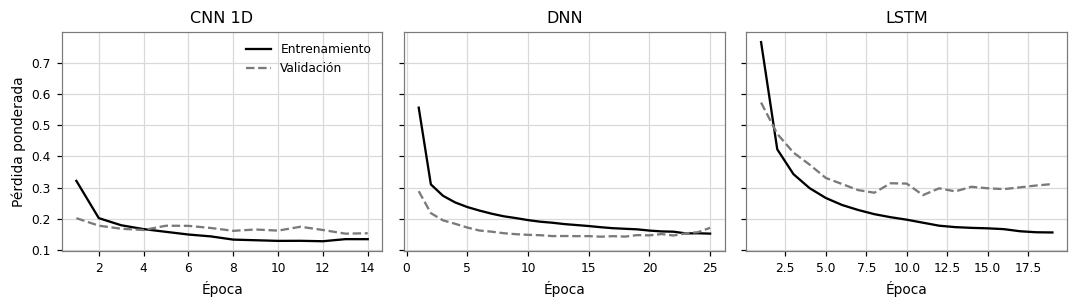

,F1 de entrenamiento,F1 de validación,F1 de prueba,Épocas,Brecha entrenamiento - validación,Brecha validación - prueba
Modelo,,,,,,
CNN 1D,"0,9292","0,9241","0,8549","10,5714","0,0051","0,0691"
DNN,"0,9287","0,9272","0,8548","17,1429","0,0015","0,0725"
LSTM,"0,9137","0,8771","0,8423",15,"0,0367","0,0348"


**Interpretación.** Las curvas promedian la pérdida de las 7 semillas de cada modelo, y hay que leerlas con una salvedad: la de entrenamiento se acumula durante la época, con *dropout* activo, mientras que la de validación se calcula al cerrarla. La mayor brecha de F1 macro entre entrenamiento y validación es la de LSTM, con 0,037, y las corridas se detienen en promedio entre 10,6 y 17,1 épocas de un máximo de 50.

Lo anterior indica que esa brecha mide cuánto se ajusta cada modelo a particularidades del entrenamiento que no se trasladan a datos nuevos, de modo que una brecha alta apunta a sobreajuste y una brecha baja con F1 bajo apuntaría a subajuste. Así mismo, la diferencia entre validación y prueba llega a 0,072 en valor absoluto. Como supera δ = 0,01, el F1 de validación no sirve como estimación final: puede ser optimista porque sobre él se eligieron la época y los hiperparámetros, y además los bloques de prueba pueden ser más difíciles que los de validación, sin que esta tabla permita separar ambas causas.

Por lo anterior, se conserva la parada temprana sobre el F1 macro de validación y las comparaciones de la sección 5 se hacen solo con el F1 de prueba.

In [26]:
if hay_resultados:
    fig, ejes = plt.subplots(1, len(NOMBRES), figsize=(3.3 * len(NOMBRES), 2.9), sharey=True)
    for eje, nombre in zip(np.atleast_1d(ejes), NOMBRES):
        curvas = pd.concat([pd.DataFrame(json.loads(r.read_text(encoding="utf-8"))["curvas"]) for r in rutas_definitivas if f"_{nombre.replace(' ', '_')}_" in r.stem])
        media = curvas.groupby("epoca")[["perdida_ent", "perdida_val"]].mean()
        eje.plot(media.index, media["perdida_ent"], color=NEGRO, linestyle="-", label="Entrenamiento")
        eje.plot(media.index, media["perdida_val"], color=GRIS_MEDIO, linestyle="--", label="Validación")
        eje.set_title(nombre)
        eje.set_xlabel("Época")
    np.atleast_1d(ejes)[0].set_ylabel("Pérdida ponderada")
    np.atleast_1d(ejes)[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()
    brecha = METRICAS.groupby("Modelo").agg(**{"F1 de entrenamiento": ("F1 de entrenamiento", "mean"), "F1 de validación": ("F1 de validación", "mean"), "F1 de prueba": ("F1 macro", "mean"), "Épocas": ("Épocas", "mean")}).loc[NOMBRES]
    brecha["Brecha entrenamiento - validación"] = brecha["F1 de entrenamiento"] - brecha["F1 de validación"]
    brecha["Brecha validación - prueba"] = brecha["F1 de validación"] - brecha["F1 de prueba"]
    display(brecha.round(4))
    mayor_brecha = brecha["Brecha entrenamiento - validación"].idxmax()
    brecha_prueba = brecha["Brecha validación - prueba"].abs().max()
    interpretar(f'''**Interpretación.** Las curvas promedian la pérdida de las {len(SEMILLAS)} semillas de cada modelo, y hay que leerlas con una salvedad: la de entrenamiento se acumula durante la época, con *dropout* activo, mientras que la de validación se calcula al cerrarla. La mayor brecha de F1 macro entre entrenamiento y validación es la de {mayor_brecha}, con {num(brecha.loc[mayor_brecha, "Brecha entrenamiento - validación"], 3)}, y las corridas se detienen en promedio entre {num(brecha["Épocas"].min(), 1)} y {num(brecha["Épocas"].max(), 1)} épocas de un máximo de {MAX_EPOCAS}.

Lo anterior indica que esa brecha mide cuánto se ajusta cada modelo a particularidades del entrenamiento que no se trasladan a datos nuevos, de modo que una brecha alta apunta a sobreajuste y una brecha baja con F1 bajo apuntaría a subajuste. Así mismo, la diferencia entre validación y prueba llega a {num(brecha_prueba, 3)} en valor absoluto. {"Como supera δ = 0,01, el F1 de validación no sirve como estimación final: puede ser optimista porque sobre él se eligieron la época y los hiperparámetros, y además los bloques de prueba pueden ser más difíciles que los de validación, sin que esta tabla permita separar ambas causas." if brecha_prueba > 0.01 else "Como no supera δ = 0,01, no se aprecia un optimismo relevante por elegir la época y los hiperparámetros sobre validación."}

Por lo anterior, se conserva la parada temprana sobre el F1 macro de validación y las comparaciones de la sección 5 se hacen solo con el F1 de prueba.''')

Modelo,CNN 1D,DNN,LSTM
Blackhole,"0,8334","0,8257","0,824"
Flooding,"0,8017","0,8075","0,7824"
Normal,"0,9688","0,9739","0,9569"
Sybil,"0,8517","0,856","0,8302"
Wormhole,"0,8192","0,8108","0,8178"


,Precision,Recall,F1
Blackhole,"0,8451","0,8223","0,8334"
Flooding,"0,7209","0,9059","0,8017"
Normal,"0,9785","0,9596","0,9688"
Sybil,"0,953","0,771","0,8517"
Wormhole,"0,783","0,8592","0,8192"


Modelo,CNN 1D,DNN,LSTM
Muy cortos,"0,7921","0,724","0,7098"
Cortos,"0,8137","0,8075","0,8083"
Medianos,"0,8029","0,8295","0,7573"
Largos,"0,7536","0,7647","0,733"


,CNN 1D,DNN,LSTM
σ = 0.0,"0,8537","0,8586","0,8326"
σ = 0.1,"0,834","0,839","0,808"
σ = 0.25,"0,7622","0,7767","0,7437"
σ = 0.5,"0,6515","0,6723","0,6399"
σ = 1.0,"0,4918","0,5193","0,488"


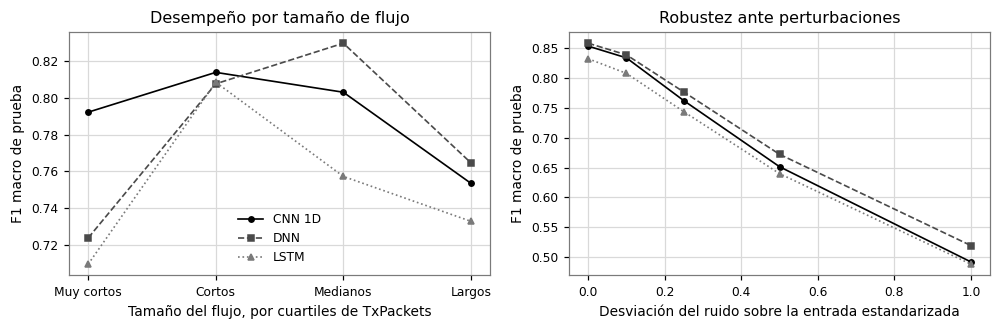

**Interpretación.** Para CNN 1D, la clase más difícil es Flooding, con F1 de 0,802, y la mayor diferencia entre precision y recall aparece en Flooding, con 0,721 y 0,906, lo que muestra hacia qué tipo de error se inclina el modelo en esa clase. Por tamaño de flujo, su F1 macro va de 0,754 en los flujos largos a 0,814 en los cortos. Con un ruido gaussiano de σ = 0,5 sobre la entrada estandarizada, el F1 macro baja 0,202 en CNN 1D, la mayor caída de los tres modelos.

En ese sentido, la comparación global oculta diferencias entre tipos de flujo, de modo que un promedio no basta para decidir dónde conviene mejorar. Hay que tener en cuenta que esta robustez se mide con los pesos de la primera semilla y con un ruido simulado, por lo que orienta la lectura, pero no reemplaza una prueba con tráfico real.

Por esta razón, lo indicado es exigir a cualquier modelo avanzado que reporte el resultado por clase y por tamaño de flujo junto con el global, y juzgar su aporte principalmente donde el baseline todavía tiene margen.

In [27]:
if hay_resultados:
    columnas_clase = [f"F1 {c}" for c in CLASES]
    por_clase = METRICAS.groupby("Modelo")[columnas_clase].mean().loc[NOMBRES].T
    por_clase.index = CLASES
    display(por_clase.round(4))
    detalle_clase = pd.DataFrame({m: [METRICAS.loc[METRICAS["Modelo"] == NOMBRES[0], f"{m} {c}"].mean() for c in CLASES] for m in ["Precision", "Recall", "F1"]}, index=CLASES)
    display(detalle_clase.round(4))
    columnas_banda = [f"F1 {b}" for b in BANDAS_FLUJO]
    por_banda = METRICAS.groupby("Modelo")[columnas_banda].mean().loc[NOMBRES].T
    por_banda.index = BANDAS_FLUJO
    display(por_banda.round(4))

    # Robustez ante perturbaciones: ruido gaussiano sobre la entrada estandarizada, con los pesos de la primera semilla
    RUIDOS = (0.0, 0.1, 0.25, 0.5, 1.0)
    robustez = {}
    for nombre in NOMBRES:
        modelo = MODELOS[nombre]()
        modelo.load_state_dict(torch.load(sorted(CORRIDAS.glob(f"definitiva_{nombre.replace(' ', '_')}_*.pt"))[0]))
        modelo.eval()
        generador_ruido = torch.Generator().manual_seed(SEMILLA)
        valores = []
        for sigma in RUIDOS:
            with torch.no_grad():
                salida = modelo(X[id_pru] + sigma * torch.randn(X[id_pru].shape, generator=generador_ruido))
            valores.append(f1_score(y_prueba, salida.argmax(1).numpy(), average="macro"))
        robustez[nombre] = valores
    robustez = pd.DataFrame(robustez, index=[f"σ = {s}" for s in RUIDOS])
    display(robustez.round(4))

    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.1))
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        ejes[0].plot(BANDAS_FLUJO, por_banda[nombre], label=nombre, markersize=3.5, linewidth=1.1, **estilo)
        ejes[1].plot(RUIDOS, robustez[nombre], label=nombre, markersize=3.5, linewidth=1.1, **estilo)
    ejes[0].set(xlabel="Tamaño del flujo, por cuartiles de TxPackets", ylabel="F1 macro de prueba", title="Desempeño por tamaño de flujo")
    ejes[1].set(xlabel="Desviación del ruido sobre la entrada estandarizada", ylabel="F1 macro de prueba", title="Robustez ante perturbaciones")
    ejes[0].legend(frameon=False)
    plt.tight_layout()
    plt.show()

    mejor = NOMBRES[0]
    clase_dificil = por_clase[mejor].idxmin()
    clase_sesgada = (detalle_clase["Precision"] - detalle_clase["Recall"]).abs().idxmax()
    banda_dificil = por_banda[mejor].idxmin()
    caida = robustez.loc["σ = 0.0"] - robustez.loc["σ = 0.5"]
    interpretar(f'''**Interpretación.** Para {mejor}, la clase más difícil es {clase_dificil}, con F1 de {num(por_clase.loc[clase_dificil, mejor], 3)}, y la mayor diferencia entre precision y recall aparece en {clase_sesgada}, con {num(detalle_clase.loc[clase_sesgada, "Precision"], 3)} y {num(detalle_clase.loc[clase_sesgada, "Recall"], 3)}, lo que muestra hacia qué tipo de error se inclina el modelo en esa clase. Por tamaño de flujo, su F1 macro va de {num(por_banda[mejor].min(), 3)} en los flujos {banda_dificil.lower()} a {num(por_banda[mejor].max(), 3)} en los {por_banda[mejor].idxmax().lower()}. Con un ruido gaussiano de σ = 0,5 sobre la entrada estandarizada, el F1 macro baja {num(caida[mejor], 3)} en {mejor}{", la mayor caída de los tres modelos" if caida.idxmax() == mejor else f", y la mayor caída es de {num(caida.max(), 3)}, en {caida.idxmax()}"}.

En ese sentido, la comparación global oculta diferencias entre tipos de flujo, de modo que un promedio no basta para decidir dónde conviene mejorar. Hay que tener en cuenta que esta robustez se mide con los pesos de la primera semilla y con un ruido simulado, por lo que orienta la lectura, pero no reemplaza una prueba con tráfico real.

Por esta razón, lo indicado es exigir a cualquier modelo avanzado que reporte el resultado por clase y por tamaño de flujo junto con el global, y juzgar su aporte principalmente donde el baseline todavía tiene margen.''')

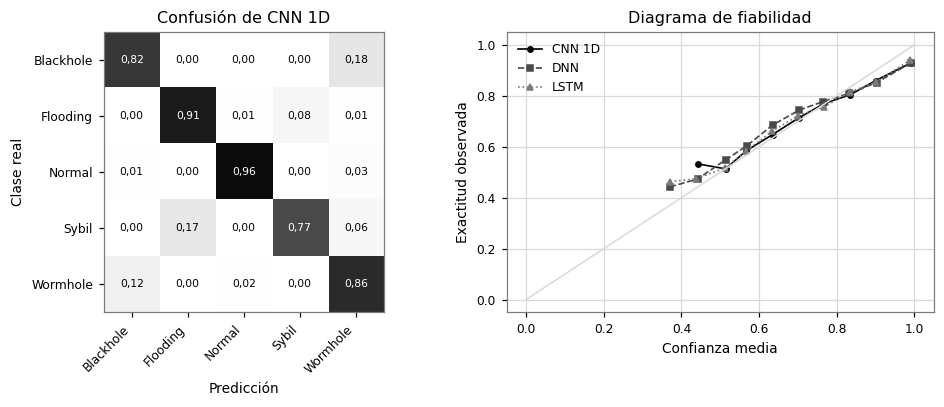

**Interpretación.** La matriz acumula las 7 semillas de CNN 1D y se normaliza por fila, de modo que la diagonal es la exhaustividad de cada clase. La confusión más frecuente es la de Blackhole predicha como Wormhole, en el 17,6 % de sus muestras. En calibración, el error esperado $ECE = \sum_b \frac{n_b}{n} |\mathrm{acc}(b) - \mathrm{conf}(b)|$ va de 0,040 a 0,052, y el mayor corresponde a DNN.

Esto significa que el error no se reparte al azar, sino que se concentra en pares concretos, lo que orienta dónde buscar la mejora. Así mismo, un ECE alto indica que las probabilidades del modelo no se pueden leer como frecuencias, aunque la clase predicha sea correcta, y esto importa porque el Entregable 3 lleva el modelo a un tablero donde se muestra esa confianza.

En consecuencia, se decide reportar el ECE junto con el F1 macro y dejar la recalibración como una decisión posterior, ajustada solo con validación, sin que altere el baseline de este entregable.

In [28]:
if hay_resultados:
    mejor = NOMBRES[0]
    acumulada = sum(confusion_matrix(y_prueba, PROBABILIDADES[(mejor, s)].argmax(1), labels=range(len(CLASES))) for s in SEMILLAS)
    normalizada = acumulada / acumulada.sum(1, keepdims=True)
    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.8))
    ejes[0].imshow(normalizada, vmin=0, vmax=1)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ejes[0].text(j, i, f"{normalizada[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=7, color="white" if normalizada[i, j] > 0.55 else "black")
    ejes[0].set(xticks=range(len(CLASES)), yticks=range(len(CLASES)), xlabel="Predicción", ylabel="Clase real", title=f"Confusión de {mejor}")
    ejes[0].set_xticklabels(CLASES, rotation=45, ha="right")
    ejes[0].set_yticklabels(CLASES)
    ejes[0].grid(False)

    bordes = np.linspace(0, 1, 16)
    for nombre, estilo in zip(NOMBRES, ESTILOS):
        probabilidad = np.vstack([PROBABILIDADES[(nombre, s)] for s in SEMILLAS])
        verdad = np.tile(y_prueba, len(SEMILLAS))
        confianza, acierto = probabilidad.max(1), probabilidad.argmax(1) == verdad
        puntos = [(confianza[(confianza > a) & (confianza <= b)].mean(), acierto[(confianza > a) & (confianza <= b)].mean()) for a, b in zip(bordes[:-1], bordes[1:]) if ((confianza > a) & (confianza <= b)).sum() > 50]
        ejes[1].plot(*zip(*puntos), label=nombre, markersize=3.5, linewidth=1.1, **estilo)
    ejes[1].plot([0, 1], [0, 1], color=GRIS_CLARO, linewidth=1)
    ejes[1].set(xlabel="Confianza media", ylabel="Exactitud observada", title="Diagrama de fiabilidad")
    ejes[1].legend(frameon=False)
    plt.tight_layout()
    plt.show()

    sin_diagonal = normalizada.copy()
    np.fill_diagonal(sin_diagonal, 0)
    real, predicho = np.unravel_index(int(np.argmax(sin_diagonal)), sin_diagonal.shape)
    ece = METRICAS.groupby("Modelo")["ECE"].mean().loc[NOMBRES]
    peor_ece = ece.idxmax()
    interpretar(f'''**Interpretación.** La matriz acumula las {len(SEMILLAS)} semillas de {mejor} y se normaliza por fila, de modo que la diagonal es la exhaustividad de cada clase. La confusión más frecuente es la de {CLASES[real]} predicha como {CLASES[predicho]}, en el {num(100 * sin_diagonal[real, predicho], 1)} % de sus muestras. En calibración, el error esperado $ECE = \\sum_b \\frac{{n_b}}{{n}} |\\mathrm{{acc}}(b) - \\mathrm{{conf}}(b)|$ va de {num(ece.min(), 3)} a {num(ece.max(), 3)}, y el mayor corresponde a {peor_ece}.

Esto significa que el error no se reparte al azar, sino que se concentra en pares concretos, lo que orienta dónde buscar la mejora. Así mismo, un ECE alto indica que las probabilidades del modelo no se pueden leer como frecuencias, aunque la clase predicha sea correcta, y esto importa porque el Entregable 3 lleva el modelo a un tablero donde se muestra esa confianza.

En consecuencia, se decide reportar el ECE junto con el F1 macro y dejar la recalibración como una decisión posterior, ajustada solo con validación, sin que altere el baseline de este entregable.''')

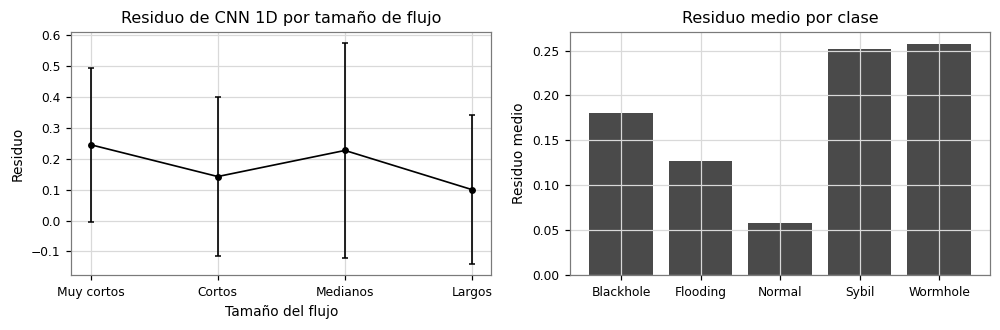

**Interpretación.** En clasificación, el residuo de una muestra se define como $1 - p_\theta(y_i \mid x_i)$, la probabilidad que el modelo no asignó a su clase real, promediada entre semillas. Para CNN 1D, el residuo medio va de 0,100 a 0,245 entre rangos de tamaño de flujo, con un ρ de Spearman de -0,259 frente a `TxPackets` (p < 0,001), y la prueba de Levene entre rangos da p < 0,001. Por clase, el residuo medio va de 0,058 a 0,258, y el mayor corresponde a Wormhole.

Esto significa que el residuo tiene estructura, porque depende del tamaño del flujo y no se comporta como un error aleatorio. Así mismo, la dispersión cambia entre rangos, es decir, hay heterocedasticidad, de modo que un promedio global describe mal a cada rango. Hay que tener en cuenta que la diferencia entre clases mide un sesgo que persiste pese a la ponderación de la pérdida.

Por tal motivo, se reportan los resultados por tamaño de flujo y por clase, y no solo el promedio global.

In [29]:
if hay_resultados:
    # En clasificación, el residuo de una muestra es la probabilidad que el modelo no asignó a su clase real
    mejor = NOMBRES[0]
    filas_prueba = np.arange(len(y_prueba))
    residuo = np.mean([1 - PROBABILIDADES[(mejor, s)][filas_prueba, y_prueba] for s in SEMILLAS], axis=0)
    grupos_banda = [residuo[banda_prueba == b] for b in range(len(BANDAS_FLUJO))]
    medias_residuo = np.array([g.mean() for g in grupos_banda])
    por_clase_residuo = pd.Series(residuo).groupby(y_prueba).mean().reindex(range(len(CLASES)))
    fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.1))
    ejes[0].errorbar(BANDAS_FLUJO, medias_residuo, yerr=[g.std() for g in grupos_banda], color=NEGRO, linestyle="-", marker="o", markersize=3.5, capsize=2, linewidth=1.1)
    ejes[0].set(xlabel="Tamaño del flujo", ylabel="Residuo", title=f"Residuo de {mejor} por tamaño de flujo")
    ejes[1].bar(CLASES, por_clase_residuo.to_numpy(), color=GRIS_OSCURO)
    ejes[1].set(ylabel="Residuo medio", title="Residuo medio por clase")
    plt.tight_layout()
    plt.show()
    rho_residuo, p_rho_residuo = stats.spearmanr(tx_prueba, residuo)
    _, p_levene = stats.levene(*grupos_banda, center="median")
    lectura_estructura = "Esto significa que el residuo tiene estructura, porque depende del tamaño del flujo y no se comporta como un error aleatorio" if p_rho_residuo < ALFA else "Esto significa que no se detecta una relación monótona entre el residuo y el tamaño del flujo"
    lectura_varianza = "Así mismo, la dispersión cambia entre rangos, es decir, hay heterocedasticidad, de modo que un promedio global describe mal a cada rango" if p_levene < ALFA else "Así mismo, no se detecta que la dispersión cambie entre rangos"
    interpretar(f'''**Interpretación.** En clasificación, el residuo de una muestra se define como $1 - p_\\theta(y_i \\mid x_i)$, la probabilidad que el modelo no asignó a su clase real, promediada entre semillas. Para {mejor}, el residuo medio va de {num(medias_residuo.min(), 3)} a {num(medias_residuo.max(), 3)} entre rangos de tamaño de flujo, con un ρ de Spearman de {num(rho_residuo, 3)} frente a `TxPackets` ({valor_p(p_rho_residuo)}), y la prueba de Levene entre rangos da {valor_p(p_levene)}. Por clase, el residuo medio va de {num(por_clase_residuo.min(), 3)} a {num(por_clase_residuo.max(), 3)}, y el mayor corresponde a {CLASES[int(np.nanargmax(por_clase_residuo.to_numpy()))]}.

{lectura_estructura}. {lectura_varianza}. Hay que tener en cuenta que la diferencia entre clases mide un sesgo que persiste pese a la ponderación de la pérdida.

Por tal motivo, se reportan los resultados por tamaño de flujo y por clase, y no solo el promedio global.''')

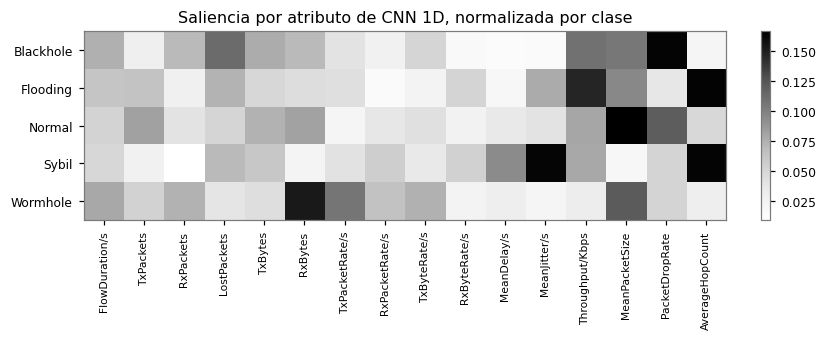

,"Blackhole, acierto",Blackhole predicho como Wormhole,"Wormhole, acierto",|fallo - acierto|
MeanPacketSize,"-1,38","0,59","0,59","1,97"
AverageHopCount,"-0,51","1,07","1,21","1,58"
LostPackets,"0,09","-0,63","-0,63","0,72"
TxPackets,"-0,46","-1,09","-1,09","0,63"
MeanJitter/s,"-0,02","-0,6","0,57","0,58"
RxBytes,"-0,59","-1,14","-0,96","0,55"


**Interpretación.** El mapa muestra, para CNN 1D con la semilla 2001, el valor medio de $|\partial f_c / \partial x_j|$ sobre los aciertos de cada clase. El atributo con más saliencia es `PacketDropRate` en Blackhole y `RxBytes` en Wormhole. La tabla contrasta, en desviaciones estándar frente a la media de entrenamiento, los 946 flujos de Blackhole predichos como Wormhole, que es el error más frecuente, con los aciertos de ambas clases; la mayor diferencia está en `MeanPacketSize`.

Es decir, los errores se concentran en flujos cuyos atributos se parecen más a los de la otra clase, lo cual es coherente con el ruido de etiquetas y el solapamiento de la sección {ref}`2.1.2 <sec-2-1-2>`. Hay que tener en cuenta que la saliencia es una derivada local, y que orienta la lectura, pero no demuestra por sí sola la ausencia de atajos.

Con base en esto, se propone contrastar esta inspección con el análisis de atajos de la sección {ref}`2.1.4 <sec-2-1-4>`, y mantener esa auditoría en los modelos avanzados del Entregable 2.

In [30]:
RUTAS_PESOS = sorted(CORRIDAS.glob("definitiva_*.pt"))
if hay_resultados and RUTAS_PESOS:
    mejor = NOMBRES[0]
    pesos = [r for r in RUTAS_PESOS if f"_{mejor.replace(' ', '_')}_" in r.stem]
    modelo = MODELOS[mejor]()
    modelo.load_state_dict(torch.load(pesos[0]))
    modelo.eval()
    semilla_pesos = int(pesos[0].stem.split("_")[-1])
    pred = PROBABILIDADES[(mejor, semilla_pesos)].argmax(1)
    ATRIBUTOS_NOMBRES = [str(a) for a in preparados["atributos"]]
    saliencia = np.zeros((len(CLASES), N_ATRIBUTOS))
    rng_cualitativo = np.random.default_rng(SEMILLA)
    for c in range(len(CLASES)):
        filas_clase = rng_cualitativo.permutation(np.flatnonzero((y_prueba == c) & (pred == c)))[:2000]
        entrada = X[id_pru[filas_clase]].clone().requires_grad_(True)
        modelo(entrada)[:, c].sum().backward()
        saliencia[c] = entrada.grad.abs().mean(0).numpy()
    saliencia = saliencia / saliencia.sum(1, keepdims=True)
    fig, eje = plt.subplots(figsize=(7.6, 3.2))
    imagen = eje.imshow(saliencia, aspect="auto")
    eje.set_xticks(range(N_ATRIBUTOS), ATRIBUTOS_NOMBRES, rotation=90, fontsize=7)
    eje.set_yticks(range(len(CLASES)), CLASES)
    eje.grid(False)
    eje.set_title(f"Saliencia por atributo de {mejor}, normalizada por clase")
    fig.colorbar(imagen, fraction=0.03)
    plt.tight_layout()
    plt.show()
    principales = {CLASES[c]: ATRIBUTOS_NOMBRES[int(saliencia[c].argmax())] for c in range(len(CLASES))}

    # Casos difíciles: el par de clases que más se confunde, comparado con los aciertos de la misma clase
    errores = confusion_matrix(y_prueba, pred, labels=range(len(CLASES))).astype(float)
    np.fill_diagonal(errores, 0)
    real, predicha = np.unravel_index(int(errores.argmax()), errores.shape)
    aciertos = id_pru.numpy()[(y_prueba == real) & (pred == real)]
    fallos = id_pru.numpy()[(y_prueba == real) & (pred == predicha)]
    otra_clase = id_pru.numpy()[(y_prueba == predicha) & (pred == predicha)]
    contraste = pd.DataFrame({f"{CLASES[real]}, acierto": np.median(X[aciertos].numpy(), axis=0), f"{CLASES[real]} predicho como {CLASES[predicha]}": np.median(X[fallos].numpy(), axis=0), f"{CLASES[predicha]}, acierto": np.median(X[otra_clase].numpy(), axis=0)}, index=ATRIBUTOS_NOMBRES)
    contraste["|fallo - acierto|"] = (contraste.iloc[:, 1] - contraste.iloc[:, 0]).abs()
    display(contraste.sort_values("|fallo - acierto|", ascending=False).head(6).round(2))
    atributo_error = contraste["|fallo - acierto|"].idxmax()
    del modelo
    interpretar(f'''**Interpretación.** El mapa muestra, para {mejor} con la semilla {semilla_pesos}, el valor medio de $|\\partial f_c / \\partial x_j|$ sobre los aciertos de cada clase. El atributo con más saliencia es `{principales[CLASES[0]]}` en {CLASES[0]} y `{principales[CLASES[-1]]}` en {CLASES[-1]}. La tabla contrasta, en desviaciones estándar frente a la media de entrenamiento, los {num(len(fallos), 0)} flujos de {CLASES[real]} predichos como {CLASES[predicha]}, que es el error más frecuente, con los aciertos de ambas clases; la mayor diferencia está en `{atributo_error}`.

Es decir, los errores se concentran en flujos cuyos atributos se parecen más a los de la otra clase, lo cual es coherente con el ruido de etiquetas y el solapamiento de la sección 2.1.2. Hay que tener en cuenta que la saliencia es una derivada local, y que orienta la lectura, pero no demuestra por sí sola la ausencia de atajos.

Con base en esto, se propone contrastar esta inspección con el análisis de atajos de la sección 2.1.4, y mantener esa auditoría en los modelos avanzados del Entregable 2.''')
elif hay_resultados:
    print("Análisis cualitativo pendiente: requiere los pesos de la primera semilla")